# Лабораторная работа №4

## GAN и Image-to-Image Translation

**Тема**. Генеративно-состязательные сети. GAN. Pix2Pix. Image-to-Image Translation

**Задание**. Выбрать предметную область, в которой необходимо генерировать или преобразовывать изображения.

In [1]:
import torch_directml

device = torch_directml.device()
print(f"Используемое устройство: {device}")

Используемое устройство: privateuseone:0


In [2]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [3]:
from torchvision.datasets import ImageFolder
from PIL import UnidentifiedImageError


class SafeImageFolder(ImageFolder):
    def __getitem__(self, index):
        try:
            return super().__getitem__(index)
        except (UnidentifiedImageError, OSError):
            print(f"[Предупреждение] Пропущен поврежденный файл по индексу {index}")
            new_index = (index + 1) % len(self)
            return self.__getitem__(new_index)

In [4]:
import torchvision.datasets as datasets

# dataset = datasets.ImageFolder(root='./data/PetImages', transform=transform)
dataset = SafeImageFolder(root='./data/PetImages', transform=transform)

## Анализ

баланс

In [5]:
from collections import Counter

print("Классы, найденные ImageFolder:", dataset.classes)
print("Индекс классов:", dataset.class_to_idx)

targets = [target for _, target in dataset.samples]
class_counts = Counter(targets)

for class_idx, count in class_counts.items():
    class_name = dataset.classes[class_idx]
    print(f"Класс '{class_name}': {count} изображений")

print(
    f"Всего изображений в датасете: {sum(class_counts.values())}"
)

Классы, найденные ImageFolder: ['Cat', 'Dog']
Индекс классов: {'Cat': 0, 'Dog': 1}
Класс 'Cat': 12500 изображений
Класс 'Dog': 12499 изображений
Всего изображений в датасете: 24999


Проверка батча

In [6]:
from torch.utils.data import DataLoader

dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)

images, labels = next(iter(dataloader))
print(f"Форма батча с картинками: {images.shape}")
print(f"Форма батча с метками: {labels.shape}")
print(f"Минимальное значение пикселя: {images.min():.4f}")
print(f"Максимальное значение пикселя: {images.max():.4f}")

Форма батча с картинками: torch.Size([64, 3, 64, 64])
Форма батча с метками: torch.Size([64])
Минимальное значение пикселя: 0.0000
Максимальное значение пикселя: 1.0000


Смотрим

In [7]:
import random
import matplotlib.pyplot as plt


def show_sample_images(dataset, n=8):
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    random_indices = [random.randint(0, len(dataset) - 1) for _ in range(n)]

    for i, idx in enumerate(random_indices):
        img, label = dataset[idx]
        img_np = img.permute(1, 2, 0).numpy()
        axes[i].imshow(img_np)
        axes[i].set_title(dataset.classes[label])
        axes[i].axis("off")
    plt.show()

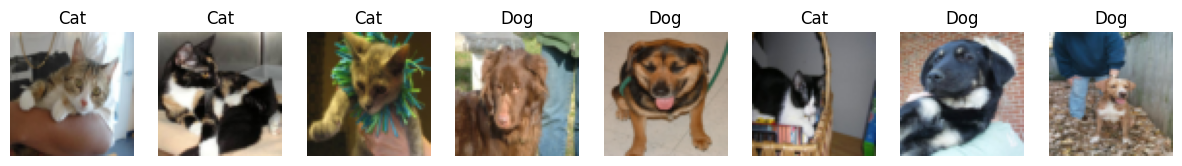

In [8]:
show_sample_images(dataset)

In [9]:
from torch.utils.data import random_split

total_len = len(dataset)
train_size = int(0.6 * total_len)
val_size = int(0.2 * total_len)
test_size = total_len - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset, [train_size, val_size, test_size]
)

## Исследование. GAN

In [10]:
BATCH_SIZE = 512

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)